# 03 — Improvements on the CNN baseline

Each variant is the CNN baseline of 02_cnn.ipynb plus one change, trained from scratch on the full dataset with seed 42.
Models are compared on validation only; the test set is used once at the end, for the baseline and the final model.

In [1]:
import os
import time
from pathlib import Path

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import PIL
import sklearn
import tensorflow as tf
import keras
from utils import CACHE, METRICS, class_weights, evaluate, load_images, plot_curves

T0 = time.time()
gpus = tf.config.list_physical_devices("GPU")
if not gpus:
    raise SystemExit("No GPU found by TensorFlow: check the kernel and the CUDA libraries (see README) before running this notebook.")
tf.config.experimental.set_memory_growth(gpus[0], True)
print("GPU:", gpus)
print("TensorFlow", tf.__version__, "| Keras", keras.__version__, "| numpy", np.__version__,
      "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__,
      "| matplotlib", matplotlib.__version__, "| Pillow", PIL.__version__)

REPORTS, MODELS = Path("reports"), Path("models")
CACHE.mkdir(exist_ok=True)
REPORTS.mkdir(exist_ok=True)
MODELS.mkdir(exist_ok=True)
SEED, SIZE, EPOCHS, BATCH, NOISE = 42, 128, 20, 32, 0.02

I0000 00:00:1791529140.123205   16303 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1791529140.883015   16303 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
TensorFlow 2.22.0-rc0 | Keras 3.16.0.dev2026100504 | numpy 2.5.3 | pandas 3.0.6 | scikit-learn 1.9.1 | matplotlib 3.11.2 | Pillow 12.3.0


In [2]:
manifest = pd.read_csv("protocol/manifest.csv")
df = manifest[manifest["drop_reason"].isna()].reset_index(drop=True)
print(pd.crosstab(df["origin"], df["split"], margins=True, margins_name="total")[["train", "val", "test", "total"]])

splits = {s: df[df["split"] == s].reset_index(drop=True) for s in ["train", "val", "test"]}
X = {s: load_images(d, SIZE) for s, d in splits.items()}
y = {s: d["label"].to_numpy() for s, d in splits.items()}
for s in X:
    print(s, X[s].shape, X[s].dtype)

split       train   val  test  total
origin                              
Painting     6997  1499  1500   9996
Photo        6995  1499  1499   9993
Schematics   6236  1336  1336   8908
Sketch        984   211   211   1406
Text         6999  1500  1500   9999
total       28211  6045  6046  40302


train (28211, 128, 128, 3) uint8
val (6045, 128, 128, 3) uint8
test (6046, 128, 128, 3) uint8


The baseline is the exact CNN of 02_cnn.ipynb, retrained here so that every row of the comparison comes from the same run conditions.
Training uses class-weighted binary cross-entropy, and validation gets the same sample weights so the two losses are comparable.
Variants are switched on by flags of one build function, so each differs from the baseline by a single change.

In [3]:
def build_cnn(name, dropout=False, l2=False, augment=False, gap=False):
    keras.utils.set_random_seed(SEED)
    reg = keras.regularizers.l2(1e-4) if l2 else None
    layers = [keras.Input((SIZE, SIZE, 3)), keras.layers.Rescaling(1 / 255)]
    if augment:  # active only in training
        layers += [keras.layers.RandomFlip("horizontal", seed=SEED), keras.layers.RandomRotation(0.05, seed=SEED),
                   keras.layers.RandomZoom(0.1, seed=SEED)]
    for filters in [16, 32, 64]:
        layers += [keras.layers.Conv2D(filters, 3, activation="relu", kernel_regularizer=reg), keras.layers.MaxPooling2D()]
    layers += [keras.layers.GlobalAveragePooling2D() if gap else keras.layers.Flatten(),
               keras.layers.Dense(64, activation="relu", kernel_regularizer=reg)]
    if dropout:
        layers.append(keras.layers.Dropout(0.5))
    layers.append(keras.layers.Dense(1, activation="sigmoid", kernel_regularizer=reg))
    model = keras.Sequential(layers, name="".join(ch if ch.isalnum() else "_" for ch in name))
    model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="binary_crossentropy", metrics=["accuracy"])
    return model

cw = class_weights(y["train"])
sw_val = np.where(y["val"] == 1, cw[1], cw[0])
print("class weights:", {k: round(v, 3) for k, v in cw.items()})

def run(name, early_stopping=False, **flags):
    model = build_cnn(name, **flags)
    cb = [keras.callbacks.EarlyStopping("val_loss", patience=3, restore_best_weights=True)] if early_stopping else []
    t = time.time()
    hist = model.fit(X["train"], y["train"], validation_data=(X["val"], y["val"], sw_val), epochs=EPOCHS,
                     batch_size=BATCH, class_weight=cw, callbacks=cb, verbose=0)
    val = evaluate(y["val"], model.predict(X["val"], verbose=0), splits["val"]["origin"])
    train_acc = ((model.predict(X["train"], verbose=0).ravel() >= 0.5) == y["train"]).mean()
    res = {"model": model, "history": hist.history, "val": val, "train_acc": train_acc, "time_s": time.time() - t,
           "epochs": len(hist.history["loss"]), "params": model.count_params(),
           "flags": {**flags, "early_stopping": early_stopping}}
    print(f"{name:22s}: {res['time_s']:.0f} s | {res['epochs']:2d} epochs | {res['params']:,} params | "
          f"train acc {train_acc:.4f} | val acc {val['accuracy']:.4f} | val balanced acc {val['balanced_acc']:.4f}")
    return res

runs = {"baseline": run("baseline")}
runs["baseline"]["model"].summary()

class weights: {0: 0.665, 1: 2.017}


baseline              : 137 s | 20 epochs | 826,529 params | train acc 0.9943 | val acc 0.8921 | val balanced acc 0.8588


Model: "baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 126, 126, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       802,880 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,479,589 (9.46 MB)

 Trainable params: 826,529 (3.15 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 1,653,060 (6.31 MB)

Each variant adds one change to the baseline: Dropout(0.5) after Dense(64), L2 (1e-4) on Conv2D and Dense kernels, early stopping on validation loss (patience 3, best weights restored), augmentation layers, or GlobalAveragePooling2D instead of Flatten.
Early stopping and augmentation do not change the number of parameters.

In [4]:
VARIANTS = {
    "a. dropout 0.5": dict(dropout=True),
    "b. L2 1e-4": dict(l2=True),
    "c. early stopping": dict(early_stopping=True),
    "d. augmentation": dict(augment=True),
    "e. global avg pooling": dict(gap=True),
}
for name, flags in VARIANTS.items():
    runs[name] = run(name, **flags)

a. dropout 0.5        : 129 s | 20 epochs | 826,529 params | train acc 0.9601 | val acc 0.8951 | val balanced acc 0.8871


b. L2 1e-4            : 131 s | 20 epochs | 826,529 params | train acc 0.9609 | val acc 0.8758 | val balanced acc 0.8555


c. early stopping     : 50 s |  7 epochs | 826,529 params | train acc 0.8968 | val acc 0.8685 | val balanced acc 0.8857


d. augmentation       : 260 s | 20 epochs | 826,529 params | train acc 0.9200 | val acc 0.8908 | val balanced acc 0.8963


e. global avg pooling : 133 s | 20 epochs | 27,809 params | train acc 0.8922 | val acc 0.8817 | val balanced acc 0.8963


Flatten feeds 14x14x64 values into Dense(64), which holds almost all of the baseline parameters.
GlobalAveragePooling2D averages each of the 64 feature maps into one value, so Dense(64) receives 64 inputs instead of 12,544 and its weights drop by a factor of about 200.

In [5]:
base_bacc = runs["baseline"]["val"]["balanced_acc"]
gain = {k: runs[k]["val"]["balanced_acc"] - base_bacc for k in VARIANTS}
helpful = [k for k, g in gain.items() if g > NOISE]
if helpful:
    stacked = helpful
    print("Variants above noise (> 2 points of validation balanced accuracy):", helpful)
else:
    stacked = sorted(gain, key=gain.get, reverse=True)[:2]
    print("No variant is above noise (> 2 points); stacking the two best instead:", stacked)

combo_flags = {}
for k in stacked:
    combo_flags.update(VARIANTS[k])
runs["combined"] = run("combined", **combo_flags)

Variants above noise (> 2 points of validation balanced accuracy): ['a. dropout 0.5', 'c. early stopping', 'd. augmentation', 'e. global avg pooling']


combined              : 144 s | 10 epochs | 27,809 params | train acc 0.8367 | val acc 0.8342 | val balanced acc 0.8572


The final model is the non-baseline row (variant or combined) with the highest validation balanced accuracy; the test set plays no part in this choice.
The gap is train minus validation accuracy (variance); the train accuracy level itself reflects bias.

In [6]:
rows = {}
for k, r in runs.items():
    v = r["val"]
    d = v["balanced_acc"] - base_bacc
    rows[k] = {"train accuracy": r["train_acc"], "validation accuracy": v["accuracy"],
               "gap": r["train_acc"] - v["accuracy"], "val balanced accuracy": v["balanced_acc"],
               "val F1 Photo": v["f1"], "change vs baseline (points)": 100 * d,
               "above noise (2 points)?": "baseline" if k == "baseline" else ("yes" if d > NOISE else "no")}
summary = pd.DataFrame(rows).T
summary.index.name = "variant"
summary.to_csv(REPORTS / "03_summary_val.csv")
num = summary.columns[:-1]
summary[num] = summary[num].astype(float).round(4)
summary[["change vs baseline (points)"]] = summary[["change vs baseline (points)"]].astype(float).round(2)
display(summary)

final_name = max((k for k in runs if k != "baseline"), key=lambda k: runs[k]["val"]["balanced_acc"])
print("Final model (best validation balanced accuracy, excluding the baseline):", final_name, "| flags:", runs[final_name]["flags"])

,train accuracy,validation accuracy,gap,val balanced accuracy,val F1 Photo,change vs baseline (points),above noise (2 points)?
variant,,,,,,,
baseline,0.9943,0.8921,0.1022,0.8588,0.7847,0.00,baseline
a. dropout 0.5,0.9601,0.8951,0.0650,0.8871,0.8047,2.84,yes
b. L2 1e-4,0.9609,0.8758,0.0851,0.8555,0.7649,-0.33,no
c. early stopping,0.8968,0.8685,0.0283,0.8857,0.7762,2.70,yes
d. augmentation,0.9200,0.8908,0.0292,0.8963,0.8047,3.76,yes
e. global avg pooling,0.8922,0.8817,0.0105,0.8963,0.7951,3.76,yes
combined,0.8367,0.8342,0.0025,0.8572,0.7298,-0.16,no


Final model (best validation balanced accuracy, excluding the baseline): d. augmentation | flags: {'augment': True, 'early_stopping': False}


The "above noise" column was computed with a 2-point threshold; the 3-point rule applies, so only augmentation and global average pooling (+3.76) count as improvements, and dropout (+2.84) and early stopping (+2.70) do not.

What I observe

Observed:
- Augmentation and global average pooling each add 3.8 points of validation balanced accuracy, above the 3-point noise threshold.
- Dropout, early stopping, L2 and the combined model stay within noise.

Meaning: augmentation and global average pooling probably help by reducing overfitting; the other changes are not conclusive (one seed).

What I observe

Observed:
- Baseline train accuracy is 0.99 against 0.89 on validation.
- Augmentation and global average pooling lower the train accuracy and shrink this gap.

Meaning: the baseline probably has low bias and high variance (overfitting), and the gain comes from reducing variance.

Curves are class-weighted for the loss on both sides (comparable) and plain for accuracy.
Early-stopping runs stop before epoch 20, so their curves are shorter.

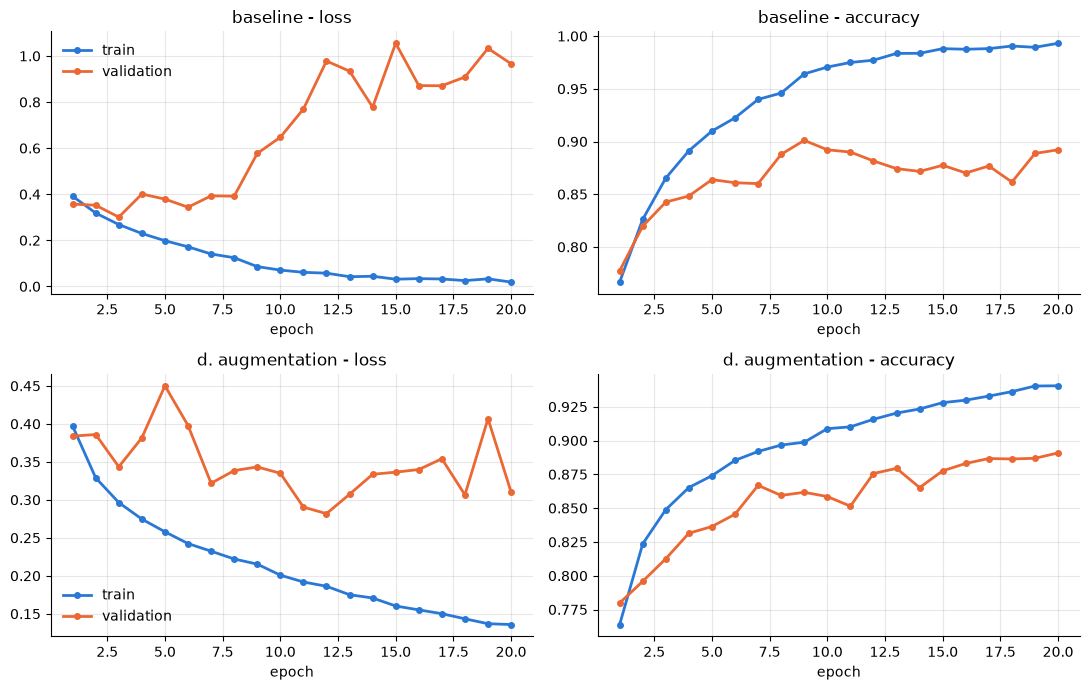

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for i, k in enumerate(["baseline", final_name]):
    plot_curves(runs[k]["history"], k, axes[i])
plt.tight_layout()
plt.savefig(REPORTS / "03_curves.png", dpi=120)
plt.show()

## Final evaluation on the test set

Test metrics are computed once here, at threshold 0.5, on the natural test distribution, for the baseline and the final model only.
The MLP and decision-tree rows are read from reports/test_results.csv (written by 01_mlp.ipynb), not recomputed; the file reports/01_mlp_test_full.csv named in the task does not exist.

In [8]:
test_eval = {k: evaluate(y["test"], runs[k]["model"].predict(X["test"], verbose=0), splits["test"]["origin"])
             for k in ["baseline", final_name]}
ref = pd.read_csv(REPORTS / "test_results.csv", index_col="model").loc[["mlp (seed 42)", "decision_tree_meta"]]
table = pd.concat([pd.DataFrame({"baseline CNN (this run)": {m: test_eval["baseline"][m] for m in METRICS},
                                 f"final CNN ({final_name})": {m: test_eval[final_name][m] for m in METRICS}}).T, ref])
table.index.name = "model"
table.round(4).to_csv(REPORTS / "03_test_results.csv")
print("Test set, full scope (n = %d)" % len(y["test"]))
display(table.round(4))

Test set, full scope (n = 6046)


,precision,recall,f1,balanced_acc,pr_auc,accuracy
model,,,,,,
baseline CNN (this run),0.7698,0.7698,0.7698,0.8470,0.8318,0.8859
final CNN (d. augmentation),0.7070,0.9079,0.7950,0.8920,0.8862,0.8839
mlp (seed 42),0.5099,0.9093,0.6534,0.8106,0.6152,0.7608
decision_tree_meta,0.9641,0.9853,0.9746,0.9866,0.9849,0.9873


What I observe

Observed:
- Final model test balanced accuracy is 0.89, against 0.85 for the baseline.
- It is above the MLP and far below the metadata tree.

Meaning: augmentation probably helps beyond noise on test too, but pixels alone stay far from the format-only bar, which suggests the tree relies on cues the CNN does not use.

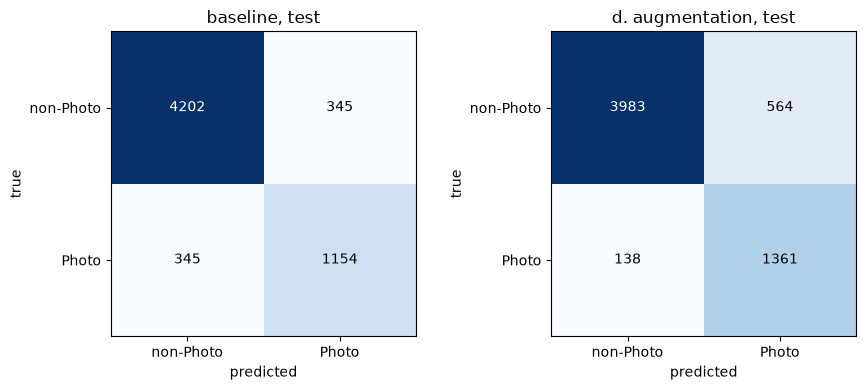

            baseline  d. augmentation
origin                               
Painting      0.2013           0.3300
Photo         0.2302           0.0921
Schematics    0.0322           0.0516
Sketch        0.0000           0.0000
Text          0.0000           0.0000


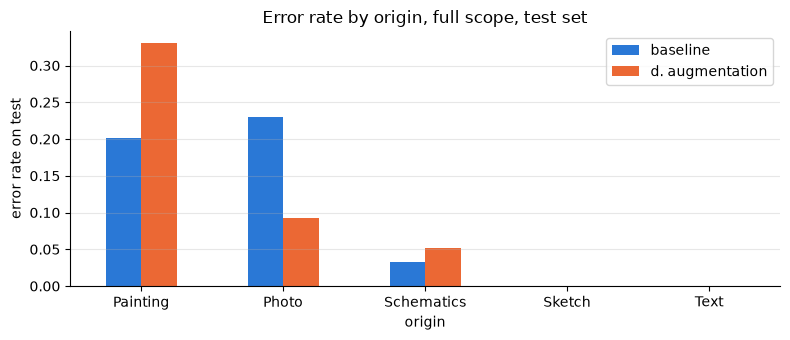

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, k in zip(axes, ["baseline", final_name]):
    cm = test_eval[k]["cm"]
    ax.imshow(cm, cmap="Blues")
    for (i, j), v in np.ndenumerate(cm):
        ax.text(j, i, v, ha="center", va="center", color="white" if v > cm.max() / 2 else "black")
    ax.set_xticks([0, 1], ["non-Photo", "Photo"])
    ax.set_yticks([0, 1], ["non-Photo", "Photo"])
    ax.set_xlabel("predicted")
    ax.set_ylabel("true")
    ax.set_title(f"{k}, test")
plt.tight_layout()
plt.savefig(REPORTS / "03_confusion.png", dpi=120)
plt.show()

err = pd.DataFrame({"baseline": test_eval["baseline"]["error_by_origin"], final_name: test_eval[final_name]["error_by_origin"]})
err.index.name = "origin"
err.round(4).to_csv(REPORTS / "03_error_by_origin.csv")
print(err.round(4))
ax = err.plot.bar(figsize=(8, 3.5), color=["#2a78d6", "#eb6834"], rot=0)
ax.set_ylabel("error rate on test")
ax.set_title("Error rate by origin, full scope, test set")
ax.grid(axis="y", alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(REPORTS / "03_error_by_origin.png", dpi=120)
plt.show()

What I observe

Observed:
- Painting error rises from 0.20 (baseline) to 0.33 with the final model.
- Photo error falls clearly.

Meaning: the final model probably trades fewer missed photos for more Paintings labelled Photo.

Saved models/final_model.keras


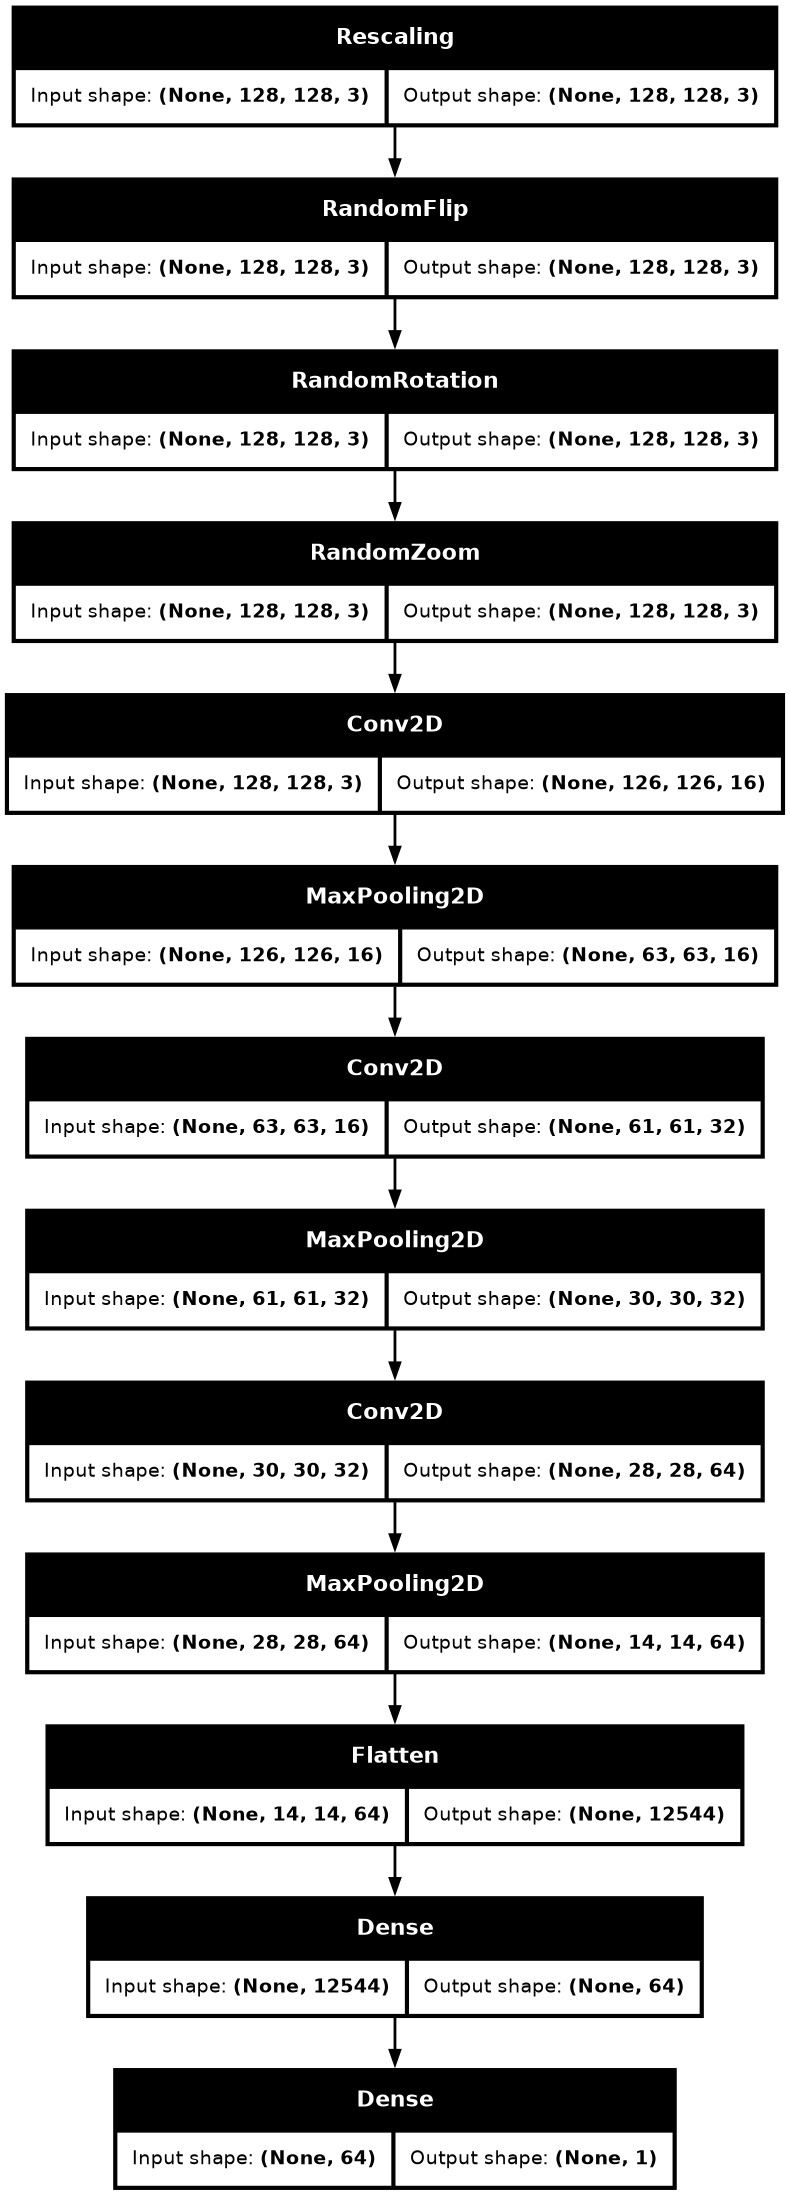

In [10]:
final_model = runs[final_name]["model"]
final_model.save(MODELS / "final_model.keras")
keras.utils.plot_model(final_model, to_file=str(REPORTS / "03_final_architecture.png"), show_shapes=True, dpi=100)
print("Saved", MODELS / "final_model.keras")
from IPython.display import Image
Image(str(REPORTS / "03_final_architecture.png"))

## Limits

One seed (42) only: variants that differ by less than 3 points of balanced accuracy are not conclusive.
Images are resized to 128x128 without keeping the aspect ratio, so shape information is distorted.
The metadata tree reaches 0.9866 balanced accuracy on test, so format and resolution cues may explain part of the CNN scores.
To check: this notebook does not test that.

In [11]:
print(f"Total notebook runtime: {(time.time() - T0) / 60:.1f} min")

Total notebook runtime: 16.5 min
